# 5. One network for many contracts

So far every network hedged a single option: one strike, one maturity, a call. A desk holds many contracts, and training one network per contract does not scale. This part asks whether **one** policy, trained on a few contracts, can hedge contracts it has never seen.

We go back to the simulated Black–Scholes market of part 3 ($\sigma = 35\%$, 30 trading dates, 1% transaction costs, $\mathrm{AVaR}_{0.9}$), where the benchmarks are well understood, so that contract generalisation is studied on its own.

In [1]:
from itertools import product

import numpy as np
import torch
import matplotlib.pyplot as plt

from deephedge import simulate
from deephedge.benchmarks import band_holdings, delta_holdings, time_to_maturity
from deephedge.losses import avar, grouped_avar_objective, hedging_loss, turnover
from deephedge.models import PositionHedge
from deephedge.plotting import COLORS, INK, MUTED, style, save
from deephedge.stats import avar_ratio_interval
from deephedge.train import fit

N, T, sigma, eps, alpha = 30, 0.25, 0.35, 0.01, 0.9
C_GRID = np.round(np.arange(0.0, 0.401, 0.025), 3)


def paired_interval(X_ref, X_new):
    # simulated paths are independent: plain paired bootstrap (blocks of one path)
    return avar_ratio_interval(X_ref, X_new, block=1, n_rep=500)

## 5.1 One network across strikes

**Training.** The 100,000 training paths of part 3, split evenly between five strikes, $K \in \{0.90, 0.95, 1.00, 1.05, 1.10\}$. Each network now also sees the log-moneyness $\log(S_{t_j}/K)$. The objective is the mean of the five strike-conditional AVaRs, each with its own threshold, so that no strike dominates because its losses are larger.

**Test.** Fresh paths, on the five training strikes, on four strikes in between ($K = 0.925, \dots, 1.075$, interpolation) and on two outside the range ($K = 0.85$ and $1.15$, extrapolation). For every test strike, delta and band know the strike; the band width $c$ is tuned on independent validation paths for that strike, never on the test paths.

In [2]:
K_TRAIN = torch.tensor([0.90, 0.95, 1.00, 1.05, 1.10], dtype=torch.float64)
K_INTERP, K_EXTRAP = [0.925, 0.975, 1.025, 1.075], [0.85, 1.15]
K_EVAL = sorted(K_TRAIN.tolist() + K_INTERP + K_EXTRAP)
group_of = lambda k: "extrapolation" if k in K_EXTRAP else "interpolation" if k in K_INTERP else "seen"

S_train = simulate.gbm_paths(100_000, seed=0)
k_id = torch.randperm(len(S_train), generator=torch.Generator().manual_seed(1212)) % 5
K_train = K_TRAIN[k_id]
S_val = simulate.gbm_paths(10_000, seed=1213)
S_test = simulate.gbm_paths(100_000, seed=1313)

moneyness = lambda S, K: torch.log(S[:, :-1] / torch.as_tensor(K).reshape(-1, 1))[..., None].float()


def train_strikes(seed):
    torch.manual_seed(seed)
    model = PositionHedge(S_train.float(), moneyness(S_train, K_train), n_thresholds=5)
    objective = lambda m, s, z, k, g: grouped_avar_objective(hedging_loss(m(s, z), s, K=k, eps=eps)[0], m.w, g, alpha)
    return fit(model, (S_train.float(), moneyness(S_train, K_train), K_train.float(), k_id), objective, progress=False)[0]


def deep_loss(model, S, K, Z):
    with torch.no_grad():
        H = model(S.float(), Z).double()
    return hedging_loss(H, S, K=K, eps=eps)[0]


def tuned_c(S, K, T=T, kind=1):
    scores = [avar(hedging_loss(band_holdings(S, eps, c, sigma, K, T, kind), S, K, kind, eps)[0], alpha) for c in C_GRID]
    return C_GRID[int(np.argmin(scores))]


universal = train_strikes(seed=12)

strike_rows = []
print(f"{'':14s}{'K':>7s}{'delta':>10s}{'band':>10s}{'deep':>10s}{'vs band':>9s}{'95% interval':>18s}")
for k in K_EVAL:
    c = tuned_c(S_val, k)
    X_delta = hedging_loss(delta_holdings(S_test, sigma, K=k), S_test, K=k, eps=eps)[0]
    X_band = hedging_loss(band_holdings(S_test, eps, c, sigma, K=k), S_test, K=k, eps=eps)[0]
    X_deep = deep_loss(universal, S_test, k, moneyness(S_test, k))
    (lo, hi), _ = paired_interval(X_band, X_deep)
    a = [avar(x, alpha) for x in (X_delta, X_band, X_deep)]
    strike_rows.append(dict(K=k, group=group_of(k), c=c, delta=a[0], band=a[1], deep=a[2], gain=a[2] / a[1] - 1, lo=lo, hi=hi))
    interval = f"[{lo:+.2%}, {hi:+.2%}]"
    print(f"{group_of(k):14s}{k:7.3f}{a[0]:10.5f}{a[1]:10.5f}{a[2]:10.5f}{a[2] / a[1] - 1:+9.2%}{interval:>18s}")

                    K     delta      band      deep  vs band      95% interval


extrapolation   0.850   0.21255   0.20733   0.20896   +0.79%  [+0.70%, +0.86%]


seen            0.900   0.17970   0.17336   0.17063   -1.57%  [-1.67%, -1.48%]


interpolation   0.925   0.16474   0.15805   0.15506   -1.89%  [-2.00%, -1.78%]


seen            0.950   0.15089   0.14386   0.14057   -2.29%  [-2.41%, -2.16%]


interpolation   0.975   0.13814   0.13091   0.12716   -2.86%  [-3.00%, -2.73%]


... (2 outputs left out)

seen            1.050   0.10654   0.09947   0.09244   -7.07%  [-7.24%, -6.89%]


interpolation   1.075   0.09799   0.09114   0.08282   -9.12%  [-9.33%, -8.92%]


seen            1.100   0.09029   0.08378   0.07414  -11.51%[-11.73%, -11.27%]


extrapolation   1.150   0.07686   0.07113   0.06120  -13.96%[-14.31%, -13.63%]


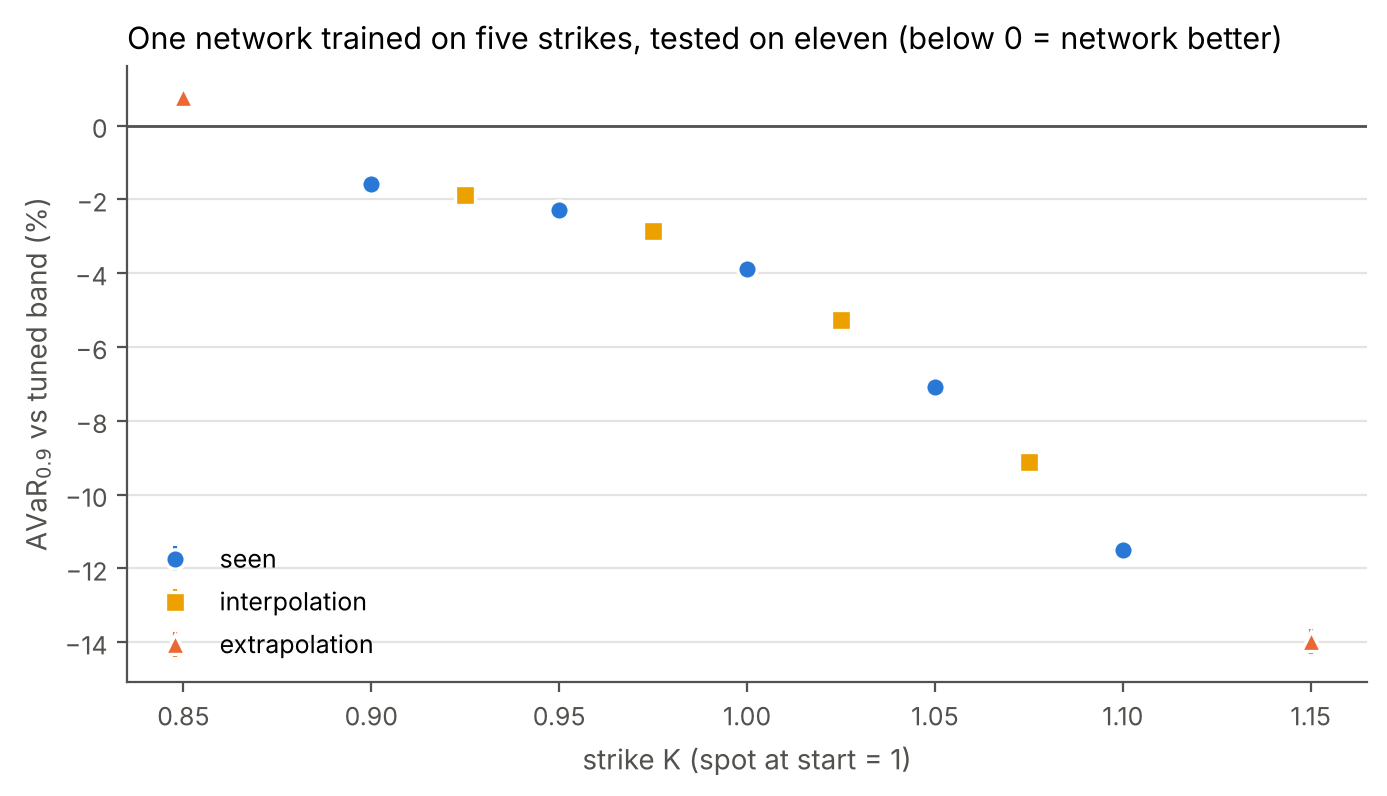

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for group, color, marker in [("seen", COLORS["deep"], "o"), ("interpolation", COLORS["other"], "s"),
                             ("extrapolation", COLORS["band"], "^")]:
    rows = [r for r in strike_rows if r["group"] == group]
    g = np.array([100 * r["gain"] for r in rows])
    ax.errorbar([r["K"] for r in rows], g, yerr=[g - 100 * np.array([r["lo"] for r in rows]),
                                                 100 * np.array([r["hi"] for r in rows]) - g],
                fmt=marker, ms=7, color=color, mec="white", mew=1.2, elinewidth=1.5, capsize=0, label=group)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("strike K (spot at start = 1)")
ax.set_ylabel("AVaR$_{0.9}$ vs tuned band (%)")
ax.set_title("One network trained on five strikes, tested on eleven (below 0 = network better)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="lower left")
style(ax)
save(fig, "part5_strikes")
plt.show()

One network trained on five strikes beats the tuned band on ten of the eleven test strikes, including the four it never saw between the training strikes. The gain grows with the strike, from 1.6% at $K = 0.90$ to 11.5% at $K = 1.10$, and is largest for out-of-the-money calls. Outside the training range the picture splits: at $K = 1.15$ the network still gains 14%, at $K = 0.85$ it is 0.8% worse than the band, a small but significant loss. The intervals are narrow because they only measure the noise of the 100,000 test paths, not the variation between training runs (next cell).

In [4]:
seed_gains = {12: [r["gain"] for r in strike_rows]}
for seed in [13, 14]:
    m = train_strikes(seed)
    seed_gains[seed] = [avar(deep_loss(m, S_test, r["K"], moneyness(S_test, r["K"])), alpha) / r["band"] - 1
                        for r in strike_rows]
print(f"{'K':>7s}" + "".join(f"{f'seed {s}':>10s}" for s in seed_gains))
for i, r in enumerate(strike_rows):
    print(f"{r['K']:7.3f}" + "".join(f"{seed_gains[s][i]:+10.2%}" for s in seed_gains))

      K   seed 12   seed 13   seed 14
  0.850    +0.79%    +0.59%    +1.30%
  0.900    -1.57%    -1.59%    -1.58%
  0.925    -1.89%    -1.83%    -1.83%
  0.950    -2.29%    -2.21%    -2.18%
  0.975    -2.86%    -2.83%    -2.79%
  1.000    -3.88%    -3.82%    -3.82%
  1.025    -5.27%    -5.07%    -5.18%
  1.050    -7.07%    -6.90%    -6.92%
  1.075    -9.12%    -8.94%    -8.95%
  1.100   -11.51%   -11.39%   -11.36%
  1.150   -13.96%   -12.85%   -10.17%


Inside the training range the gains move by at most 0.2 points from one seed to another. Outside it they are less stable: at $K = 1.15$ the gain ranges from 10% to 14%, and at $K = 0.85$ the network is worse than the band for every seed (+0.6% to +1.3%). Extrapolation works in one direction and not in the other.

## 5.2 Is one network as good as one network per strike?

A fair comparison needs the same amount of training. The universal network sees 100,000 paths for 30 epochs, that is 3,000 optimiser updates. A specialist trained on the 20,000 paths of a single strike for the same 30 epochs makes only 600 updates. We therefore train each specialist twice: 30 epochs, and 150 epochs (3,000 updates), keeping the checkpoint with the best validation AVaR.

In [5]:
def train_specialist(k, n_epochs, seed=12):
    if k in K_TRAIN.tolist():
        S_k = S_train[k_id == K_TRAIN.tolist().index(k)]                     # the paths of this strike
    else:
        subset = torch.randperm(len(S_train), generator=torch.Generator().manual_seed(12000 + round(1000 * k)))
        S_k = S_train[subset[:20_000]]                                          # same size, never test paths
    torch.manual_seed(seed)
    model = PositionHedge(S_k.float(), moneyness(S_k, k))
    objective = lambda m, s, z: grouped_avar_objective(hedging_loss(m(s, z), s, K=k, eps=eps)[0], m.w,
                                                        torch.zeros(len(s), dtype=torch.long), alpha)
    long_run = n_epochs > 30
    validate = (lambda m: avar(deep_loss(m, S_val, k, moneyness(S_val, k)), alpha)) if long_run else None
    milestones = (90, 125) if long_run else (18, 25)
    return fit(model, (S_k.float(), moneyness(S_k, k)), objective, n_epochs=n_epochs, milestones=milestones,
               validate=validate, progress=False)[0]


print(f"{'K':>7s}{'':16s}{'band':>10s}{'universal':>11s}{'spec. 30 ep.':>14s}{'spec. 150 ep.':>15s}{'universal vs matched':>22s}")
for k in [0.85, 0.925, 1.0, 1.075, 1.15]:
    r = next(r for r in strike_rows if r["K"] == k)
    a_30 = avar(deep_loss(train_specialist(k, 30), S_test, k, moneyness(S_test, k)), alpha)
    a_150 = avar(deep_loss(train_specialist(k, 150), S_test, k, moneyness(S_test, k)), alpha)
    print(f"{k:7.3f}{r['group']:>16s}{r['band']:10.5f}{r['deep']:11.5f}{a_30:14.5f}{a_150:15.5f}{r['deep'] / a_150 - 1:+22.2%}")

      K                      band  universal  spec. 30 ep.  spec. 150 ep.  universal vs matched


  0.850   extrapolation   0.20733    0.20896       0.21241        0.20488                +1.99%


  0.925   interpolation   0.15805    0.15506       0.16101        0.15523                -0.11%


  1.000            seen   0.11922    0.11459       0.11930        0.11469                -0.09%


  1.075   interpolation   0.09114    0.08282       0.08713        0.08287                -0.06%


  1.150   extrapolation   0.07113    0.06120       0.06277        0.05871                +4.24%


At equal epochs the universal network looks better than every specialist, by up to 4%. That comparison is unfair: the specialist made five times fewer updates. With the same budget the difference vanishes inside the training range (within 0.1%). Only at the two extrapolated strikes is a specialist trained on that very strike better, by 2% to 4%, which is expected since it has seen the contract. On the tested contracts, the universal network achieves comparable AVaR to specialised networks at a matched optimisation budget.

## 5.3 Strikes, maturities, calls and puts

A harder test: one network for 12 contracts, three strikes ($0.9, 1, 1.1$) × two maturities (6 weeks and 6 months) × calls and puts, 5,000 training paths each. Each network sees the log-moneyness, the time to maturity and the option type. Checkpoints are selected on validation paths.

The inputs are put on fixed scales instead of being standardised date by date. With only two training maturities, date-by-date standardisation turns the time to maturity into a binary $\pm 1$ at every date, even just before expiry, and the network then fails to interpolate to a 3-month maturity (in a first version it did 7–17% worse than the band). With a fixed scale the time to maturity shrinks smoothly towards zero for every contract.

The test contracts were never seen: strikes $0.95$ and $1.05$, maturity 3 months, calls and puts. The benchmark is the band with one width for calls and one for puts, both tuned on the validation paths of the training contracts.

In [6]:
CONTRACTS = list(product([0.90, 1.00, 1.10], [0.125, 0.50], [1, -1]))
TEST_CONTRACTS = [(0.95, 0.25, 1), (0.95, 0.25, -1), (1.05, 0.25, 1), (1.05, 0.25, -1)]
name = lambda c: f"{'call' if c[2] == 1 else 'put'} K={c[0]:.2f}"

def unpack(paths):
    S, info = paths
    return S, info["K"], info["T"], info["kind"], info["group"]


S_tr, K_tr, T_tr, kind_tr, g_tr = unpack(simulate.contract_paths(CONTRACTS, 5000, seed=1301))
S_va, K_va, T_va, kind_va, g_va = unpack(simulate.contract_paths(CONTRACTS, 1000, seed=1302))
S_te, K_te, T_te, kind_te, g_te = unpack(simulate.contract_paths(TEST_CONTRACTS, 10_000, seed=1320))


def contract_features(S, K, T, kind):
    # fixed scales, the same at every date: log-moneyness / 0.2, time to maturity / 0.5, option type
    tau = time_to_maturity(T, N)
    return torch.stack([torch.log(S[:, :-1] / K[:, None]) / 0.2, tau / 0.5, kind[:, None].expand_as(tau)], dim=-1).float()


def contract_loss(model, S, K, T, kind):
    with torch.no_grad():
        H = model(S.float(), contract_features(S, K, T, kind)).double()
    return hedging_loss(H, S, K=K, kind=kind, eps=eps)[0]


def mean_group_avar(X, groups):
    return np.mean([avar(X[groups == g], alpha) for g in groups.unique()])


def train_contracts(seed):
    torch.manual_seed(seed)
    Z_tr = contract_features(S_tr, K_tr, T_tr, kind_tr)
    model = PositionHedge(S_tr.float(), Z_tr, n_thresholds=len(CONTRACTS), standardise=False)
    objective = lambda m, s, z, k, knd, g: grouped_avar_objective(hedging_loss(m(s, z), s, K=k, kind=knd, eps=eps)[0],
                                                                  m.w, g, alpha)
    validate = lambda m: mean_group_avar(contract_loss(m, S_va, K_va, T_va, kind_va), g_va)
    return fit(model, (S_tr.float(), Z_tr, K_tr.float(), kind_tr.float(), g_tr), objective, batch_size=1200,
               validate=validate, every=1, progress=False)[0]


multi = train_contracts(seed=1304)
torch.save(multi.state_dict(), "../results/models/part5_multi_contract.pt")     # reused in part 6

# band width per option type, tuned on the validation paths of the training contracts
c_type = {}
for kind in [1, -1]:
    mask = kind_va == kind
    scores = [mean_group_avar(hedging_loss(band_holdings(S_va[mask], eps, c, sigma, K_va[mask], T_va[mask], kind),
                                           S_va[mask], K_va[mask], kind, eps)[0], g_va[mask]) for c in C_GRID]
    c_type[kind] = C_GRID[int(np.argmin(scores))]
print(f"band width: calls c = {c_type[1]:.3f}, puts c = {c_type[-1]:.3f}\n")

X_te = {"delta": hedging_loss(delta_holdings(S_te, sigma, K_te, T_te, kind_te), S_te, K_te, kind_te, eps)[0],
        "band": hedging_loss(band_holdings(S_te, eps, torch.where(kind_te == 1, c_type[1], c_type[-1]), sigma,
                                           K_te, T_te, kind_te), S_te, K_te, kind_te, eps)[0],
        "deep": contract_loss(multi, S_te, K_te, T_te, kind_te)}

print(f"{'unseen contract':16s}{'delta':>10s}{'band':>10s}{'deep':>10s}{'vs delta':>10s}{'vs band':>10s}{'95% interval':>18s}")
for g, c in enumerate(TEST_CONTRACTS):
    m = g_te == g
    a = {k: avar(x[m], alpha) for k, x in X_te.items()}
    (lo, hi), _ = paired_interval(X_te["band"][m], X_te["deep"][m])
    interval = f"[{lo:+.2%}, {hi:+.2%}]"
    print(f"{name(c):16s}{a['delta']:10.5f}{a['band']:10.5f}{a['deep']:10.5f}{a['deep'] / a['delta'] - 1:+10.1%}"
          f"{a['deep'] / a['band'] - 1:+10.2%}{interval:>18s}")

band width: calls c = 0.125, puts c = 0.150



unseen contract      delta      band      deep  vs delta   vs band      95% interval
call K=0.95        0.15120   0.14446   0.14440     -4.5%    -0.04%  [-0.54%, +0.49%]


put K=0.95         0.09659   0.08959   0.08970     -7.1%    +0.12%  [-0.76%, +0.93%]
call K=1.05        0.10683   0.09903   0.09742     -8.8%    -1.62%  [-2.51%, -0.81%]


put K=1.05         0.15628   0.14807   0.14825     -5.1%    +0.12%  [-0.44%, +0.67%]


On contracts whose strike **and** maturity were never seen, the network is 4.5% to 8.8% better than delta. Against the type-specific band, the honest benchmark, it is level: within 0.1% on three contracts and 1.6% better on the call $K = 1.05$, the only significant difference for this seed.

In [7]:
print(f"{'':16s}" + "".join(f"{f'seed {s}':>11s}" for s in [1304, 1351, 1352]) + "   (deep vs band)")
models = {1304: multi, 1351: train_contracts(1351), 1352: train_contracts(1352)}
for g, c in enumerate(TEST_CONTRACTS):
    m = g_te == g
    a_band = avar(X_te["band"][m], alpha)
    row = [avar(contract_loss(models[s], S_te[m], K_te[m], T_te[m], kind_te[m]), alpha) / a_band - 1 for s in models]
    print(f"{name(c):16s}" + "".join(f"{x:+11.2%}" for x in row))

                  seed 1304  seed 1351  seed 1352   (deep vs band)


call K=0.95          -0.04%     -0.63%     -0.41%
put K=0.95           +0.12%     -0.98%     +0.41%
call K=1.05          -1.62%     -3.47%     -2.73%


put K=1.05           +0.12%     -0.51%     -0.30%


Over three seeds the network beats the band in 10 of 12 comparisons, by 0.8% on average. The call $K = 1.05$ is the only contract where the gain is clear for every seed (1.6% to 3.5%), and the first seed happens to be the weakest. The result is positive but small, of the same order as the variation between seeds.

### How does the network trade?

In [8]:
H = {"delta": delta_holdings(S_te, sigma, K_te, T_te, kind_te),
     "band": band_holdings(S_te, eps, torch.where(kind_te == 1, c_type[1], c_type[-1]), sigma, K_te, T_te, kind_te)}
with torch.no_grad():
    H["deep"] = multi(S_te.float(), contract_features(S_te, K_te, T_te, kind_te)).double()

print(f"{'':16s}{'':7s}{'mean cost':>11s}{'turnover':>10s}{'trades < 0.01':>15s}{'mean |H - delta|':>18s}")
for g, c in enumerate(TEST_CONTRACTS):
    m = g_te == g
    for k in ["delta", "band", "deep"]:
        costs = hedging_loss(H[k][m], S_te[m], K_te[m], kind_te[m], eps)[1]
        small = ((H[k][m][:, 1:] - H[k][m][:, :-1]).abs() < 0.01).double().mean()
        print(f"{name(c) if k == 'delta' else '':16s}{k:7s}{costs.mean():11.5f}{turnover(H[k][m]).mean():10.3f}"
              f"{small:15.1%}{(H[k][m] - H['delta'][m]).abs().mean():18.4f}")

                         mean cost  turnover  trades < 0.01  mean |H - delta|
call K=0.95     delta      0.02891     2.874          21.6%            0.0000
                band       0.02173     2.137          53.5%            0.0325
                deep       0.02090     2.058          27.7%            0.0582
put K=0.95      delta      0.02291     2.399          21.9%            0.0000
                band       0.01507     1.595          57.2%            0.0372
                deep       0.01518     1.585          27.9%            0.0650
call K=1.05     delta      0.02535     2.436          21.8%            0.0000


                band       0.01785     1.702          53.0%            0.0322
                deep       0.01732     1.670          27.4%            0.0677
put K=1.05      delta      0.02834     2.864          21.7%            0.0000
                band       0.02016     2.062          56.5%            0.0371
                deep       0.01894     1.936          26.8%            0.0662


The network and the band trade about as much (1.6 to 2.1 shares over the life of the option), but differently. The band does nothing on more than half of the dates and moves to the edge of its band when it trades. The network almost always adjusts, by small amounts, and stays further from delta than the band does. It reaches similar costs with a smooth policy rather than a no-trade region.

Part 6 removes the last simplification of this part: a known, constant volatility.